<a href="https://colab.research.google.com/github/Riky-18/RNN-LSTM-Task/blob/main/RNN_LSTM_Task4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q gradio

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Dropout

import warnings
warnings.filterwarnings('ignore')

# Seaborn theme setting
sns.set_theme(style="whitegrid")
print("✅ All required libraries imported successfully!")

✅ All required libraries imported successfully!


In [2]:
# Cell 2: Data Loading & Cleaning
# Note: daily-minimum-temperatures-in-me.csv file-ah Colab environment-la upload panni irukkanum
df = pd.read_csv('daily-minimum-temperatures-in-me.csv')

# Column names rename panrom for simplicity
df.columns = ['Date', 'Temp']

# '?' symbols irundha remove panni float-ah convert panrom
df['Temp'] = df['Temp'].astype(str).str.replace('?', '', regex=False)
df['Temp'] = pd.to_numeric(df['Temp'], errors='coerce')

# Missing values irundha forward-fill panrom
df['Temp'] = df['Temp'].ffill()

# Date-ah datetime format-ku maathi Index-ah set panrom
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (3650, 1)


,Temp
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8


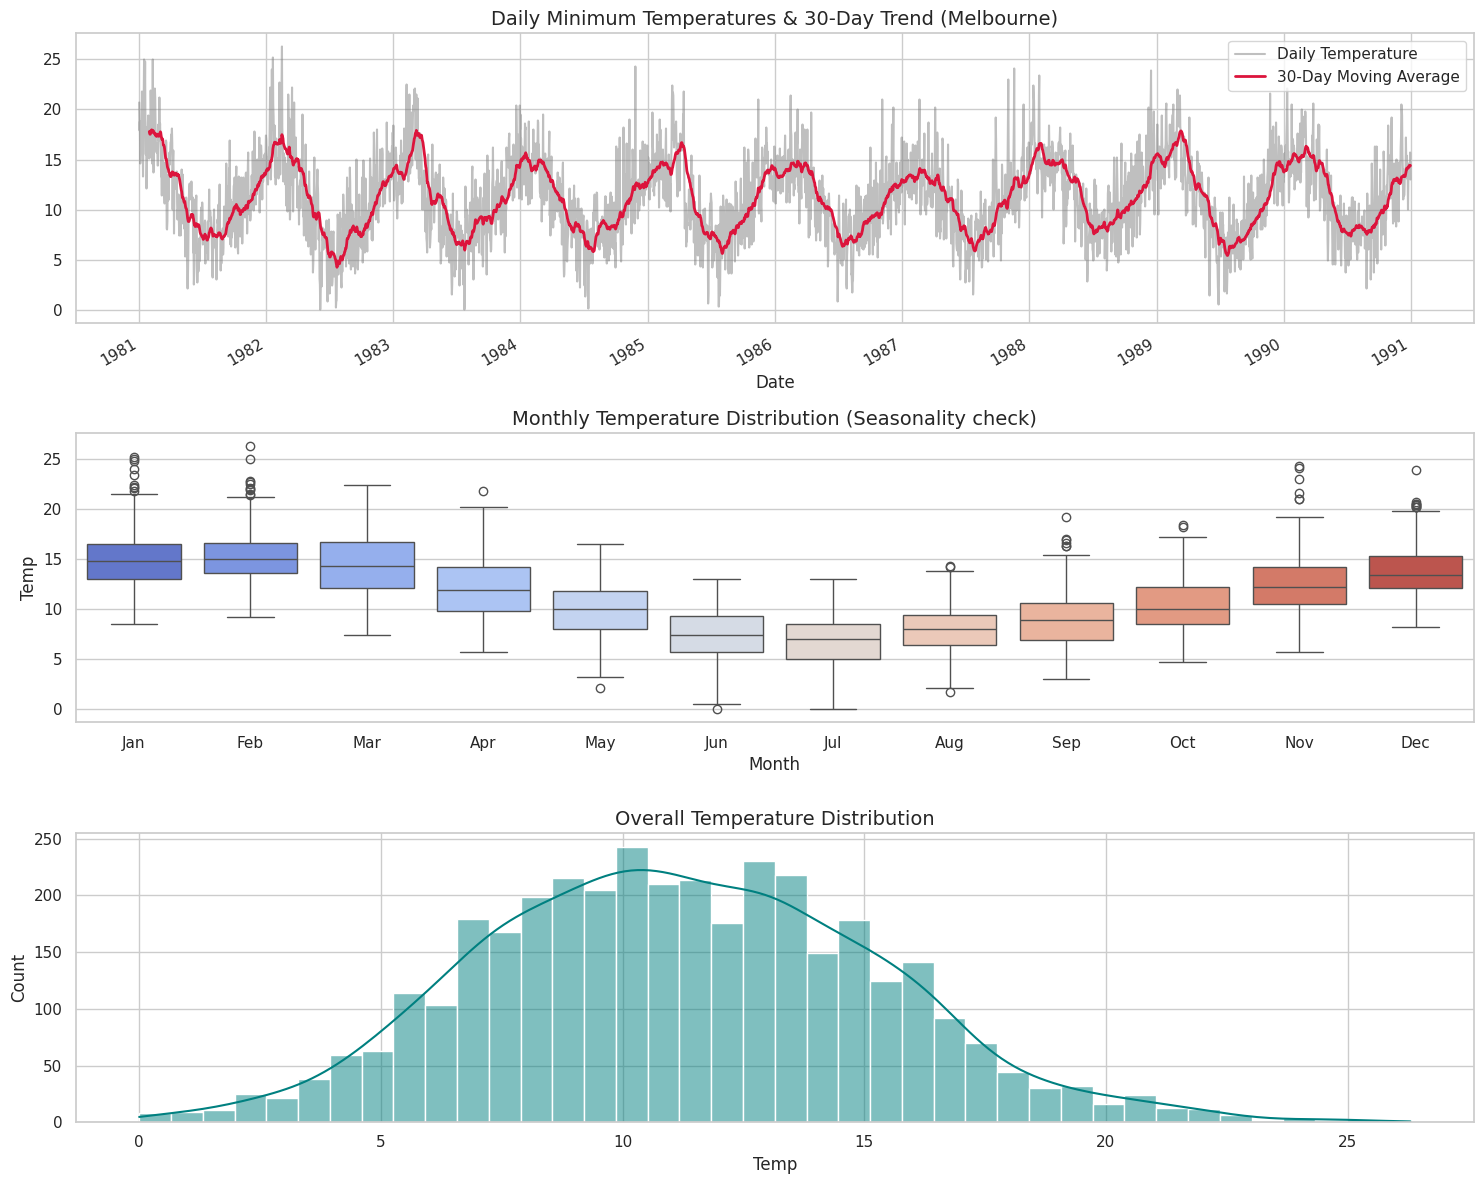

In [3]:
# Cell 3: Comprehensive EDA
fig, axes = plt.subplots(3, 1, figsize=(15, 12))

# 1. Full Line Chart with 30-day Rolling Mean
axes[0].plot(df.index, df['Temp'], label='Daily Temperature', alpha=0.5, color='gray')
df['Temp'].rolling(window=30).mean().plot(ax=axes[0], label='30-Day Moving Average', color='crimson', lw=2)
axes[0].set_title('Daily Minimum Temperatures & 30-Day Trend (Melbourne)', fontsize=14)
axes[0].legend()

# 2. Seasonality Boxplot by Month
df['Month'] = df.index.month
sns.boxplot(x='Month', y='Temp', data=df, ax=axes[1], palette='coolwarm')
axes[1].set_title('Monthly Temperature Distribution (Seasonality check)', fontsize=14)
axes[1].set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])

# 3. KDE & Histogram (Distribution)
sns.histplot(df['Temp'], kde=True, ax=axes[2], color='teal', bins=40)
axes[2].set_title('Overall Temperature Distribution', fontsize=14)

plt.tight_layout()
plt.show()

In [4]:
# Cell 4: Feature Engineering
df_feat = df.copy()

# Date based features
df_feat['DayOfWeek'] = df_feat.index.dayofweek
df_feat['DayOfYear'] = df_feat.index.dayofyear

# Lag features (Past values)
df_feat['Lag_1'] = df_feat['Temp'].shift(1)
df_feat['Lag_7'] = df_feat['Temp'].shift(7)
df_feat['Lag_30'] = df_feat['Temp'].shift(30)

# Rolling Window Features
df_feat['Rolling_Mean_7'] = df_feat['Temp'].rolling(window=7).mean()
df_feat['Rolling_Std_7'] = df_feat['Temp'].rolling(window=7).std()

# Shift vachadhum starting rows NaN aagidum, adha drop panrom
df_feat.dropna(inplace=True)

print("Engineered Data Preview:")
display(df_feat.head(3))

Engineered Data Preview:


,Temp,Month,DayOfWeek,DayOfYear,Lag_1,Lag_7,Lag_30,Rolling_Mean_7,Rolling_Std_7
Date,,,,,,,,,
1981-01-31,15.4,1,5,31,15.1,16.0,20.7,16.828571,1.690872
1981-02-01,15.3,2,6,32,15.4,16.5,17.9,16.657143,1.787789
1981-02-02,18.8,2,0,33,15.3,18.7,18.8,16.671429,1.807129


In [5]:
# Cell 5: Train-Test Split and Sequence Windowing
# Univariate forecasting-ku Temp column-ah scale panrom
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_temp = scaler.fit_transform(df[['Temp']])

# Train: 80%, Test: 20% (Time series-la shuffle panna koodadhu)
train_size = int(len(scaled_temp) * 0.8)
train_data, test_data = scaled_temp[0:train_size], scaled_temp[train_size:]

# Sliding Window Function
def create_sequences(dataset, window_size=30):
    X, y = [], []
    for i in range(len(dataset) - window_size):
        X.append(dataset[i : i + window_size, 0])
        y.append(dataset[i + window_size, 0])
    return np.array(X), np.array(y)

WINDOW_SIZE = 30
X_train, y_train = create_sequences(train_data, WINDOW_SIZE)
X_test, y_test = create_sequences(test_data, WINDOW_SIZE)

# Deep Learning-ku 3D Shape-ku reshape panrom: [samples, time_steps, 1]
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape},  y_test shape:  {y_test.shape}")

X_train shape: (2890, 30, 1), y_train shape: (2890,)
X_test shape:  (700, 30, 1),  y_test shape:  (700,)


In [6]:
# Cell 6: SimpleRNN Model
tf.random.set_seed(42)

rnn_model = Sequential([
    SimpleRNN(units=64, return_sequences=True, input_shape=(WINDOW_SIZE, 1)),
    Dropout(0.2),
    SimpleRNN(units=32),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

rnn_model.compile(optimizer='adam', loss='mean_squared_error')
print("--- Training SimpleRNN ---")
rnn_history = rnn_model.fit(
    X_train, y_train,
    epochs=25,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

--- Training SimpleRNN ---
Epoch 1/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 9s 41ms/step - loss: 0.0407 - val_loss: 0.0202
Epoch 2/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0190 - val_loss: 0.0152
Epoch 3/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - loss: 0.0160 - val_loss: 0.0119
Epoch 4/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - loss: 0.0138 - val_loss: 0.0128
Epoch 5/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0129 - val_loss: 0.0113
Epoch 6/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.0119 - val_loss: 0.0138
Epoch 7/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0118 - val_loss: 0.0133
Epoch 8/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0115 - val_loss: 0.0135
Epoch 9/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0108 - val_loss: 0.0121
Epoch 10/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0110 - val_loss: 0.0128
Epoch 11/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0107 - val_loss: 0.0115
Epoch 12/25
82/82 ━━━━━━━━━━━━━━━━━━

In [7]:
# Cell 7: LSTM Model
tf.random.set_seed(42)

lstm_model = Sequential([
    LSTM(units=64, return_sequences=True, input_shape=(WINDOW_SIZE, 1)),
    Dropout(0.2),
    LSTM(units=32),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

lstm_model.compile(optimizer='adam', loss='mean_squared_error')
print("--- Training LSTM ---")
lstm_history = lstm_model.fit(
    X_train, y_train,
    epochs=25,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

--- Training LSTM ---
Epoch 1/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step - loss: 0.0313 - val_loss: 0.0150
Epoch 2/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - loss: 0.0147 - val_loss: 0.0125
Epoch 3/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0139 - val_loss: 0.0144
Epoch 4/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0135 - val_loss: 0.0126
Epoch 5/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0131 - val_loss: 0.0131
Epoch 6/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0131 - val_loss: 0.0126
Epoch 7/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 0.0129 - val_loss: 0.0130
Epoch 8/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0128 - val_loss: 0.0128
Epoch 9/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0124 - val_loss: 0.0130
Epoch 10/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0123 - val_loss: 0.0120
Epoch 11/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0120 - val_loss: 0.0118
Epoch 12/25
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s

22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step
📊 SimpleRNN -> RMSE: 2.552 | MAE: 2.043
📊 LSTM      -> RMSE: 2.546 | MAE: 2.021


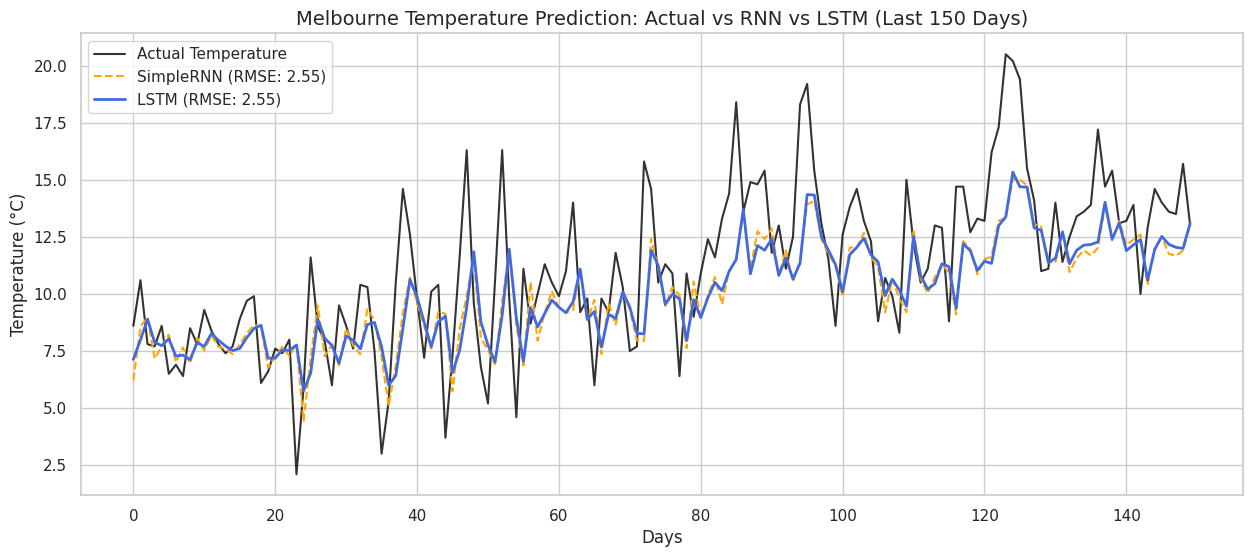

In [8]:
# Cell 8: Predictions and Inverse Scaling
rnn_preds = rnn_model.predict(X_test)
lstm_preds = lstm_model.predict(X_test)

# Scale-ah reverse panni actual temperature units-ku maathuvom
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))
rnn_preds_actual = scaler.inverse_transform(rnn_preds)
lstm_preds_actual = scaler.inverse_transform(lstm_preds)

# Evaluation Metrics Calculation
def get_metrics(actual, pred):
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mae = mean_absolute_error(actual, pred)
    return rmse, mae

rnn_rmse, rnn_mae = get_metrics(y_test_actual, rnn_preds_actual)
lstm_rmse, lstm_mae = get_metrics(y_test_actual, lstm_preds_actual)

print("="*40)
print(f"📊 SimpleRNN -> RMSE: {rnn_rmse:.3f} | MAE: {rnn_mae:.3f}")
print(f"📊 LSTM      -> RMSE: {lstm_rmse:.3f} | MAE: {lstm_mae:.3f}")
print("="*40)

# Plotting Comparison
plt.figure(figsize=(15, 6))
plt.plot(y_test_actual[-150:], label='Actual Temperature', color='black', alpha=0.8)
plt.plot(rnn_preds_actual[-150:], label=f'SimpleRNN (RMSE: {rnn_rmse:.2f})', color='orange', linestyle='--')
plt.plot(lstm_preds_actual[-150:], label=f'LSTM (RMSE: {lstm_rmse:.2f})', color='royalblue', lw=2)
plt.title('Melbourne Temperature Prediction: Actual vs RNN vs LSTM (Last 150 Days)', fontsize=14)
plt.xlabel('Days')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.show()

In [9]:
# Cell 9: Gradio Web App
import gradio as gr

def predict_next_day(model_choice, last_30_days_str):
    try:
        # User input comma-separated string-ah list-ah parse panrom
        values = [float(x.strip()) for x in last_30_days_str.split(',')]
        if len(values) != 30:
            return f"Error: 30 values venum, aana neenga {len(values)} values kuduthirukeenga."

        # Scale and Reshape
        seq = np.array(values).reshape(-1, 1)
        scaled_seq = scaler.transform(seq).reshape(1, 30, 1)

        # Inference
        if model_choice == "SimpleRNN":
            pred = rnn_model.predict(scaled_seq)
        else:
            pred = lstm_model.predict(scaled_seq)

        result = scaler.inverse_transform(pred)[0][0]
        return f"Predicted Next Day Temperature ({model_choice}): {result:.2f} °C"
    except Exception as e:
        return f"Input Error: {str(e)}"

# Default example sample
sample_input = ",".join([str(round(x[0], 1)) for x in df[['Temp']].iloc[-30:].values])

demo = gr.Interface(
    fn=predict_next_day,
    inputs=[
        gr.Radio(["LSTM", "SimpleRNN"], label="Select Model", value="LSTM"),
        gr.Textbox(lines=3, label="Enter Past 30 Days Temperatures (Comma Separated)", value=sample_input)
    ],
    outputs="text",
    title="🌤️ Melbourne Temperature Forecasting System",
    description="Enter 30 continuous daily temperatures to forecast the 31st day minimum temperature."
)

demo.launch(debug=True, share=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://b22c234a4b673d42a7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://b22c234a4b673d42a7.gradio.live


In [ ]:
# Cell 11: Launch Streamlit with LocalTunnel
!npm install -g localtunnel
!streamlit run app.py & npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏
added 22 packages in 2s
⠏
⠏3 packages are looking for funding
⠏  run `npm fund` for details
⠏/bin/bash: line 1: streamlit: command not found
⠙⠹⠸⠼⠴⠦⠧your url is: https://polite-knives-bet.loca.lt
